In [1]:

import os
import json
import joblib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

INPUT_DIR = Path("/kaggle/input")

metadata_files = list(INPUT_DIR.rglob("metadata.json"))

if not metadata_files:
    raise FileNotFoundError(
        "metadata.json not found. "
        "Please add the processed dataset as Notebook input."
    )

DATA_DIR = metadata_files[0].parent

print("Processed dataset directory:")
print(DATA_DIR)

print("\nAvailable files:")
for file in DATA_DIR.iterdir():
    print(file.name)


Processed dataset directory:
/kaggle/input/notebooks/ahmadlmomani/00-dry-bean-eda-preprocessing/dry_bean_processed

Available files:
X_test_scaled.csv
X_test_scaled.npy
X_train_scaled.csv
X_train_scaled.npy
imputer.pkl
label_encoder.pkl
metadata.json
scaler.pkl
y_test.csv
y_test.npy
y_train.csv
y_train.npy


In [3]:

X_train = np.load(DATA_DIR / "X_train_scaled.npy")
X_test = np.load(DATA_DIR / "X_test_scaled.npy")

y_train = np.load(DATA_DIR / "y_train.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

with open(DATA_DIR / "metadata.json", "r") as f:
    metadata = json.load(f)

class_names = metadata["classes"]

print("Data loaded successfully!")

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

print("\nClasses:")
print(class_names)

print("\nNumber of Classes:", len(class_names))


Data loaded successfully!

Training Features: (10834, 16)
Testing Features: (2709, 16)
Training Labels: (10834,)
Testing Labels: (2709,)

Classes:
['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']

Number of Classes: 7


In [4]:

KERNELS = {
    "Linear": {
        "kernel": "linear",
        "C": 1.0
    },

    "Polynomial": {
        "kernel": "poly",
        "C": 1.0,
        "degree": 3,
        "gamma": "scale"
    },

    "RBF": {
        "kernel": "rbf",
        "C": 1.0,
        "gamma": "scale"
    },

    "Sigmoid": {
        "kernel": "sigmoid",
        "C": 1.0,
        "gamma": "scale"
    }
}

print("SVM Kernels configured successfully!")

for name, params in KERNELS.items():
    print(f"{name}: {params}")


SVM Kernels configured successfully!
Linear: {'kernel': 'linear', 'C': 1.0}
Polynomial: {'kernel': 'poly', 'C': 1.0, 'degree': 3, 'gamma': 'scale'}
RBF: {'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale'}
Sigmoid: {'kernel': 'sigmoid', 'C': 1.0, 'gamma': 'scale'}


In [5]:

models = {}
results = []

for kernel_name, params in KERNELS.items():

    print("\n" + "=" * 60)
    print(f"Training {kernel_name} SVM")
    print("=" * 60)

    svm = SVC(
        **params,
        class_weight=None,
        cache_size=1000
    )

    model = OneVsRestClassifier(
        svm,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    models[kernel_name] = model

    print(f"{kernel_name} training completed!")

print("\nAll SVM models trained successfully!")



Training Linear SVM
Linear training completed!

Training Polynomial SVM
Polynomial training completed!

Training RBF SVM
RBF training completed!

Training Sigmoid SVM
Sigmoid training completed!

All SVM models trained successfully!


In [6]:

for kernel_name, model in models.items():

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Kernel": kernel_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Macro F1": f1,
        "Weighted F1": weighted_f1
    })

    print(f"\n{kernel_name} Results")
    print("-" * 40)

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"Macro F1: {f1:.4f}")
    print(f"Weighted F1: {weighted_f1:.4f}")



Linear Results
----------------------------------------
Accuracy: 0.9151
Precision: 0.9299
Recall: 0.9257
Macro F1: 0.9273
Weighted F1: 0.9155

Polynomial Results
----------------------------------------
Accuracy: 0.9125
Precision: 0.9291
Recall: 0.9200
Macro F1: 0.9239
Weighted F1: 0.9120

RBF Results
----------------------------------------
Accuracy: 0.9225
Precision: 0.9354
Recall: 0.9322
Macro F1: 0.9336
Weighted F1: 0.9227

Sigmoid Results
----------------------------------------
Accuracy: 0.4806
Precision: 0.4310
Recall: 0.3903
Macro F1: 0.4073
Weighted F1: 0.4994


In [7]:

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("SVM Kernel Performance Comparison")

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}"
    })
)


SVM Kernel Performance Comparison


,Kernel,Accuracy,Precision,Recall,Macro F1,Weighted F1
0,RBF,0.9225,0.9354,0.9322,0.9336,0.9227
1,Linear,0.9151,0.9299,0.9257,0.9273,0.9155
2,Polynomial,0.9125,0.9291,0.9200,0.9239,0.9120
3,Sigmoid,0.4806,0.4310,0.3903,0.4073,0.4994


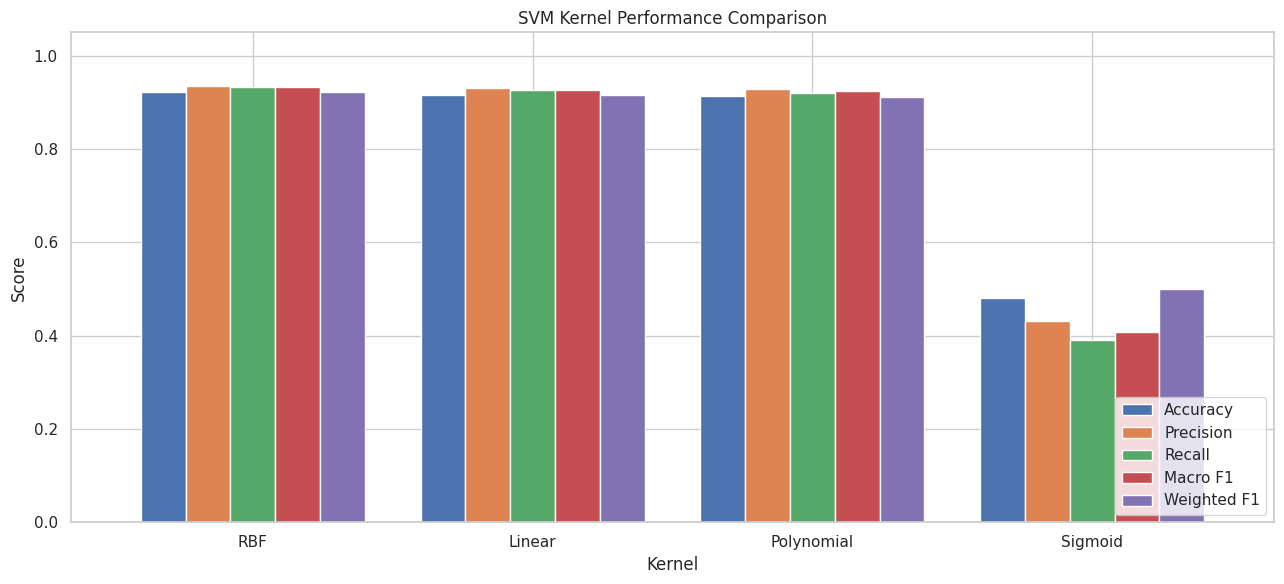

In [8]:

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "Macro F1",
    "Weighted F1"
]

results_plot = results_df.set_index("Kernel")[metrics]

ax = results_plot.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("SVM Kernel Performance Comparison")
plt.xlabel("Kernel")
plt.ylabel("Score")
plt.ylim(0, 1.05)

plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()


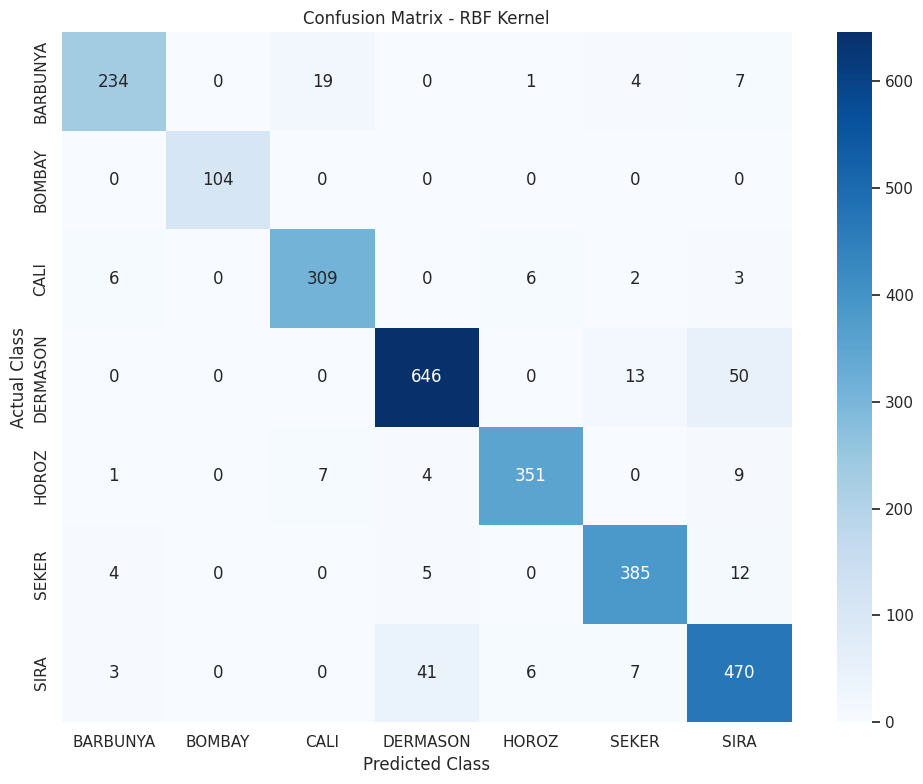

Best Kernel: RBF


In [9]:

best_kernel = results_df.iloc[0]["Kernel"]
best_model = models[best_kernel]

y_best_pred = best_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_best_pred
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(f"Confusion Matrix - {best_kernel} Kernel")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

print("Best Kernel:", best_kernel)


In [10]:

print(f"Classification Report - {best_kernel} Kernel")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_best_pred,
        target_names=class_names,
        zero_division=0
    )
)


Classification Report - RBF Kernel
              precision    recall  f1-score   support

    BARBUNYA       0.94      0.88      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.95      0.93       326
    DERMASON       0.93      0.91      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.94      0.95      0.94       406
        SIRA       0.85      0.89      0.87       527

    accuracy                           0.92      2709
   macro avg       0.94      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



In [11]:

OUTPUT_DIR = Path("/kaggle/working/svm_baseline")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save comparison results
results_df.to_csv(
    OUTPUT_DIR / "kernel_comparison.csv",
    index=False
)

# Save trained models
joblib.dump(
    models,
    OUTPUT_DIR / "svm_kernel_models.pkl"
)

# Save best model information
best_model_info = {
    "best_kernel": best_kernel,
    "best_macro_f1": float(
        results_df.iloc[0]["Macro F1"]
    ),
    "classes": class_names
}

with open(OUTPUT_DIR / "best_model_info.json", "w") as f:
    json.dump(best_model_info, f, indent=4)

# Save predictions
pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_best_pred
}).to_csv(
    OUTPUT_DIR / "best_kernel_predictions.csv",
    index=False
)

print("Baseline results saved successfully!")

for file in OUTPUT_DIR.iterdir():
    print(file.name)


Baseline results saved successfully!
best_model_info.json
kernel_comparison.csv
best_kernel_predictions.csv
svm_kernel_models.pkl
